# 05. SFT pilot reviewed dan evaluasi nyata

Tanggal client: 13 Oktober 2026. Notebook ini membaca artifact eksperimen yang sudah selesai, tanpa melatih ulang atau memperbaiki keluaran model. **TRAIN-005 smoke 3 update; TRAIN-006 pilot 40 update; test JSON valid 0/4.**

Persetujuan pengguna "aprove lanjut" berlaku untuk 12 kandidat pilot v2. Ini persetujuan paket JSON, belum hasil browser. Empat train, empat validation dan empat test tetap mengikuti keluarga sumber pretraining. Ukuran pilot belum membuktikan kemampuan membuat website.

In [1]:
from pathlib import Path
import json, sys, hashlib
ROOT = Path.cwd()
if ROOT.name == "notebooks": ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
def read(relative): return json.loads((ROOT / relative).read_text(encoding="utf-8"))
def sha(path): return hashlib.sha256(path.read_bytes()).hexdigest()
print("Interpreter:", sys.executable)
print("Root:", ROOT)
approval = read("reports/data/ANNOTATION_APPROVAL_PILOT_V2.json")
smoke = read("reports/training/TRAIN-005.json")
pilot = read("reports/training/TRAIN-006.json")
evaluation = read("reports/training/TRAIN-006_sft_evaluation.json")
profile = read("reports/training/SFT_PILOT_PROFILE_2026-10-13.json")

Interpreter: F:\Generative_AI\Vibe_Coding_Proyek_1\.venv\Scripts\python.exe
Root: F:\Generative_AI\Vibe_Coding_Proyek_1


## 1. Persetujuan dan preparation

Identitas teknis reviewer adalah `user_chat_approval`. Nama pribadi dan jawaban setiap kolom checklist tidak diberikan, sehingga tidak diisi dengan asumsi. Paket draft v2 dan worksheet kosong asli dipertahankan; reviewed copy dan worksheet keputusan disimpan di path baru. RUN-093 mencatat persetujuan, RUN-094 menyiapkan 12 accepted, nol rejected/duplicate. Tokenizer/cache dan assignment keluarga pretraining digunakan kembali.

In [2]:
print(json.dumps({k: approval[k] for k in (
    "approval_text", "scope", "reviewer", "approved_rows",
    "personal_reviewer_name_provided", "individual_checklist_provided")}, indent=2))
print("SFT split:", evaluation["sft_split_counts"])
print("Parent:", pilot["config"]["initial_checkpoint"])
lineage = pilot["config"]["lineage"]
print("Tokenizer SHA:", lineage["tokenizer_sha256"])
print("Pretrain fingerprint:", lineage["pretrain_fingerprint"]["sha256"])
print("SFT fingerprint:", lineage["sft_fingerprint"]["sha256"])
reviewed_path = ROOT / Path(approval["annotation_path"].replace("\\", "/"))
if reviewed_path.exists():
    print("Reviewed file checksum cocok:", sha(reviewed_path) == approval["annotation_sha256"])
else: print("Reviewed JSONL tetap lokal; laporan approval tersedia setelah clone.")

{
  "approval_text": "aprove lanjut",
  "scope": "all 12 candidates in pilot-id-v2",
  "reviewer": "user_chat_approval",
  "approved_rows": 12,
  "personal_reviewer_name_provided": false,
  "individual_checklist_provided": false
}
SFT split: {'train': 4, 'validation': 4, 'test': 4}
Parent: checkpoints\TRAIN-004-VERIFIED\best.pt
Tokenizer SHA: f7d5410d5963b3504bc09a4f6bf29e695cb8c6ba64041bfe1596a13cecb210d7
Pretrain fingerprint: fd6e3b5a20b3214cfd9e6cc769f7c011d3209235731edb793b917e60ca8a371a
SFT fingerprint: c53aca6888d29c73d3cca5ef01a0a6e556720d3c75dac0a60be454d1b65ef5f7
Reviewed file checksum cocok: True


## 2. Coverage dan label training

Train hanya empat contoh. `feature_grid`, `footer`, `testimonial`, dan `pricing_table` belum ada pada train pilot. Coverage seluruh pilot tidak berarti coverage train memadai. Tabel ini audit deskriptif partition; contoh validation/test tidak boleh dipindahkan ke train.

Loss dihitung pada token target JSON dan EOS. Token prompt serta padding diberi label -100. Target terlalu panjang ditolak utuh, tidak dipotong. Contoh berikut membangun satu batch di CPU bila artifact lokal tersedia.

In [3]:
for split, counts in profile["data_profile"].items():
    print(split, json.dumps(counts, ensure_ascii=False))
train_path = ROOT / "data/processed/sft/train.jsonl"
tokenizer_path = ROOT / "data/tokenizer/tokenizer.json"
if train_path.exists() and tokenizer_path.exists():
    from tokenizers import Tokenizer
    from src.data.normalize import read_jsonl
    from src.data.dataset import PageSpecDataset
    rows = list(read_jsonl(train_path))
    data = PageSpecDataset(rows, Tokenizer.from_file(str(tokenizer_path)), "sft", 1024)
    item = data[0]
    print("Shape:", tuple(item["input_ids"].shape))
    print("Target labels:", int((item["labels"] != -100).sum()))
    print("Prompt/padding masked:", int((item["labels"] == -100).sum()))
else: print("Siapkan reviewed data dan tokenizer lokal untuk melihat label batch.")

train {"rows": 4, "families": 4, "styles": {"tailwind": 2, "plain_css": 2}, "sections": {"navbar": 3, "hero": 1, "text_section": 5, "contact_form": 1}, "interactions": {"menu_toggle": 1, "form_validate": 1}}
validation {"rows": 4, "families": 4, "styles": {"tailwind": 2, "plain_css": 2}, "sections": {"feature_grid": 4, "hero": 2, "text_section": 1, "footer": 1}, "interactions": {}}
test {"rows": 4, "families": 4, "styles": {"tailwind": 2, "plain_css": 2}, "sections": {"navbar": 2, "hero": 4, "footer": 3, "text_section": 3, "feature_grid": 1}, "interactions": {}}


Shape: (1024,)
Target labels: 434
Prompt/padding masked: 590


## 3. Konfigurasi dan keputusan sebelum test

Model 14.186.496 parameter berasal dari bobot acak yang sudah dipretrain proyek 1.200 update. Smoke dan pilot sama-sama mulai dari `TRAIN-004-VERIFIED`, tidak berantai dari smoke. Pilot memakai optimizer/schedule baru: AdamW, seed 42, BF16, batch 2 x accumulation 2, context 1.024, 40 update, warmup 4, LR 1e-4 ke 1e-5, clipping 1. Validation seluruh empat contoh setiap 10 update; best dipilih dari validation saja.

Budget dan decoding test ditetapkan sebelum hasil test dilihat. Empat contoh train diulang 40 kali, sekitar 160 presentasi contoh. Banyaknya token/update bukan banyaknya contoh unik.

In [4]:
cfg = read("configs/training_sft_pilot.json")
print(json.dumps(cfg, indent=2))
for run in (smoke, pilot):
    print(json.dumps({"run": run["run_id"], "status": run["status"],
        "steps": run["global_step"], "train_tokens": run["total_train_tokens"],
        "initial_val": run["initial_validation"]["loss"],
        "final_val": run["final_validation"]["loss"], "seconds": run["wall_seconds"],
        "peak_allocated_GiB": run["peak_allocated_bytes"] / 2**30,
        "peak_reserved_GiB": run["peak_reserved_bytes"] / 2**30,
        "free_disk_GiB": run["free_bytes_after"] / 2**30}, indent=2))
print("Environment actual TRAIN-006:", json.dumps(pilot["environment"], indent=2))

{
  "mode": "sft",
  "seed": 42,
  "block_size": 1024,
  "dataset_dir": "data/processed/sft",
  "tokenizer": "data/tokenizer/tokenizer.json",
  "label_alignment": "already_shifted_next_token",
  "prompt_and_padding_label": -100,
  "oversize_json": "reject without truncation",
  "model_config_path": "configs/model.json",
  "device": "cuda",
  "precision": "bf16",
  "batch_size": 2,
  "gradient_accumulation": 2,
  "max_steps": 40,
  "warmup_steps": 4,
  "learning_rate": 0.0001,
  "min_learning_rate": 1e-05,
  "betas": [
    0.9,
    0.95
  ],
  "weight_decay": 0.1,
  "grad_clip": 1.0,
  "validation_interval": 10,
  "validation_batches": 2,
  "checkpoint_interval": 10,
  "log_interval": 5,
  "reserve_free_bytes": 16106127360,
  "experiment_scope": "approved pilot: 4 train / 4 validation / 4 test; repeated small corpus, not generalization proof",
  "selection_rule": "budget and schedule fixed before inspecting pilot test; best checkpoint selected by validation only"
}
{
  "run": "TRAIN-005

## 4. Loss aktual

Validation target loss turun 7,512 menjadi 3,739. Grafik memakai log aktual, bukan angka simulasi. Loss pretraining atas kode HTML/CSS berbeda dari loss SFT atas JSON, sehingga keduanya tidak dibandingkan langsung. Loss teacher forcing memakai token target sebelumnya yang benar; hasil autoregresif dapat gagal walaupun loss turun.

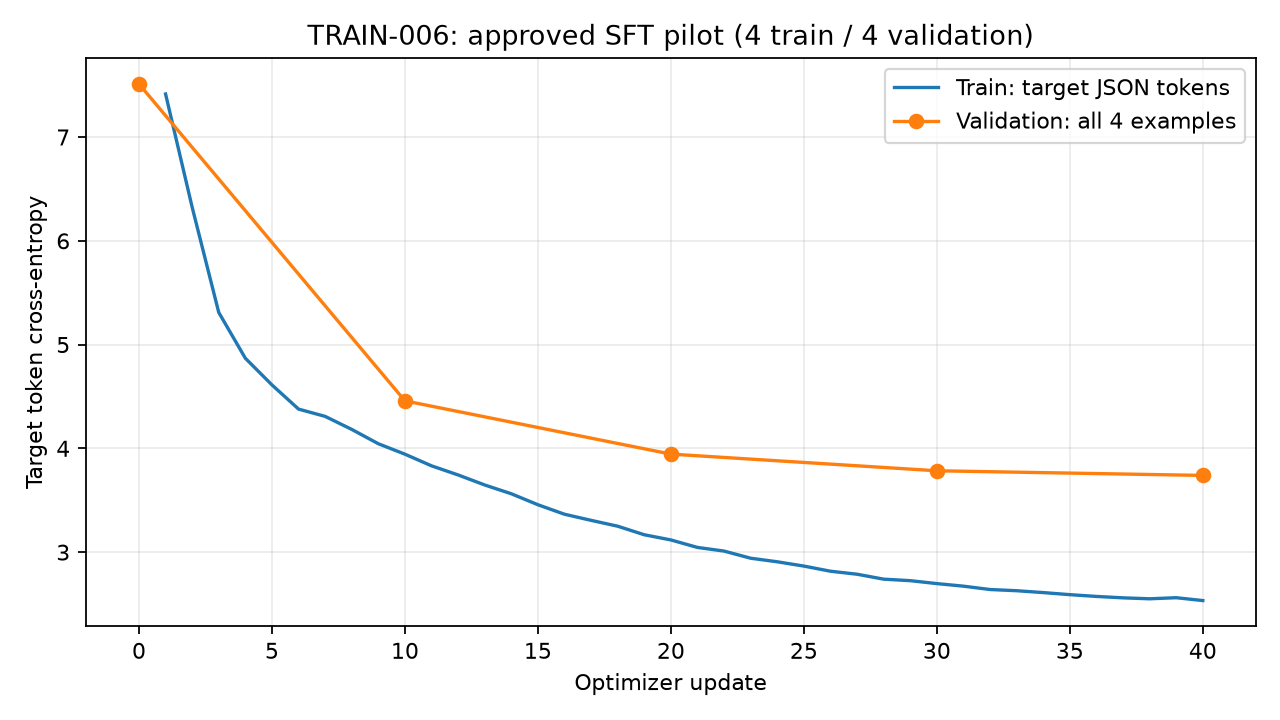

Validation points: [(0, 7.51153), (10, 4.457795), (20, 3.944593), (30, 3.783956), (40, 3.739242)]
Best step: 40
Best SHA: 74705520f6f6c543dc8d9908057769fdf81f478159efb44b6e3966ca847c5540


In [5]:
from IPython.display import display, Image
display(Image(filename=str(ROOT / "reports/training/SFT_PILOT_LOSS_2026-10-13.png")))
print("Validation points:", [(r["step"], round(r["loss"], 6)) for r in profile["curve"]["validation"]])
print("Best step:", pilot["best_checkpoint"]["global_step"])
print("Best SHA:", pilot["best_checkpoint_sha256"])

## 5. Test held-out pilot

RUN-097 memakai target-token loss pada empat test reviewed dengan ancestry/membership verified. Generasi greedy, temperature 0, max_new_tokens 768, seed 42. `generation_mode=production` adalah nama gate provenance evaluator, bukan kesiapan aplikasi.

Hasil: test loss 3,488 / perplexity 32,729 / 1.531 target labels; **JSON parseable 0/4 dan schema valid 0/4**. Selanjutnya tampilkan cuplikan raw, bukan keluaran yang diperbaiki. Keempat generasi mencapai token limit tanpa EOS. Target yang benar tidak ditampilkan sebagai hasil model.

In [6]:
print(json.dumps(evaluation, indent=2))
print("Decoding config:", json.dumps(read("configs/evaluation_sft_pilot.json"), indent=2))
raw_path = ROOT / Path(evaluation["raw_outputs_path"].replace("\\", "/"))
if raw_path.exists():
    raw = json.loads(raw_path.read_text(encoding="utf-8"))
    for row in raw["records"]:
        print("\nExample:", row["example_id"])
        print("Prompt:", row["prompt"])
        print("Generation metadata:", {k: v for k, v in row.items()
              if k not in {"target_spec", "prompt", "raw_output", "parsed_spec"} and k not in {"attribution"}})
        print("Raw preview (first 600 characters):", row["raw_output"][:600])
    print("Full unchanged outputs remain local:", raw_path)
else: print("Raw outputs tetap lokal; laporan metrik tersedia di Git.")

{
  "report_id": "TRAIN-006",
  "checkpoint": "checkpoints\\TRAIN-006\\best.pt",
  "checkpoint_sha256": "74705520f6f6c543dc8d9908057769fdf81f478159efb44b6e3966ca847c5540",
  "checkpoint_step": 40,
  "checkpoint_phase": "sft",
  "config_sha256": "e2ecc362304bcd85e85693e6ba097089b0ccd0df9aa7aeb91830f8303351342b",
  "sft_test_metrics": {
    "loss": 3.48825924385614,
    "perplexity": 32.72892501203196,
    "valid_tokens": 1531,
    "batches": 2
  },
  "sft_test_sha256": "8f469daab1a040b6c60b35ef1f64664b89ea38f9c9329acb0ae11014cb64c873",
  "sft_split_counts": {
    "train": 4,
    "validation": 4,
    "test": 4
  },
  "generation": {
    "count": 4,
    "parseable": 0,
    "schema_valid": 0,
    "parseable_rate": 0.0,
    "schema_valid_rate": 0.0,
    "generation_mode": "production",
    "checkpoint_step": 40,
    "checkpoint_sha256": "74705520f6f6c543dc8d9908057769fdf81f478159efb44b6e3966ca847c5540",
    "schema_sha256": "7a13c15552171245fa0d28876eb6bd9612ece8dddc05a330c793574950e93bb7",

## 6. Kesimpulan dan pekerjaan berikutnya

- Smoke dan training selesai pada GPU, tidak ada OOM/nonfinite. Ini bukti pipeline SFT bisa berjalan, belum kemampuan menghasilkan website.
- Pilot hanya empat train examples. Perlu perluasan train dengan provenance dan review manusia, berdasarkan katalog komponen proyek yang telah ditetapkan.
- Tetap gunakan family assignment yang sama. Jangan memasukkan target test ke train, memilih checkpoint dari test, atau mengubah decoding berdasarkan empat test ini.
- Corpus/revisi eksperimen berikutnya harus diberi ID baru. Karena test pilot sudah dibaca, hasil ulang pada test yang sama bersifat eksploratif; generalisasi memerlukan evaluasi final yang belum dipakai untuk pengembangan.
- Belum ada output yang layak dirender; browser, visual, aksesibilitas dan interaksi belum dievaluasi. Aplikasi preview/unduhan tetap tahap akhir.

Notebook 01 sampai 04 menyimpan snapshot fase terdahulu, termasuk status draft pada saat itu. Status reviewed terbaru ada pada notebook ini dan log AI-010.